Multi-Class Benchmark Classification Pipeline IRIS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
df = pd.read_csv('iris.csv')
expected = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
assert list(df.columns) == expected, f"Expected columns {expected}; found {list(df.columns)}"
display(df.head())
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nClass counts:\n", df.species.value_counts())


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Shape: (150, 5)

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


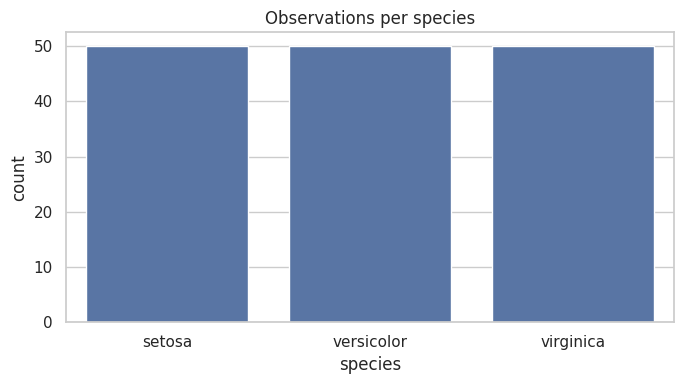

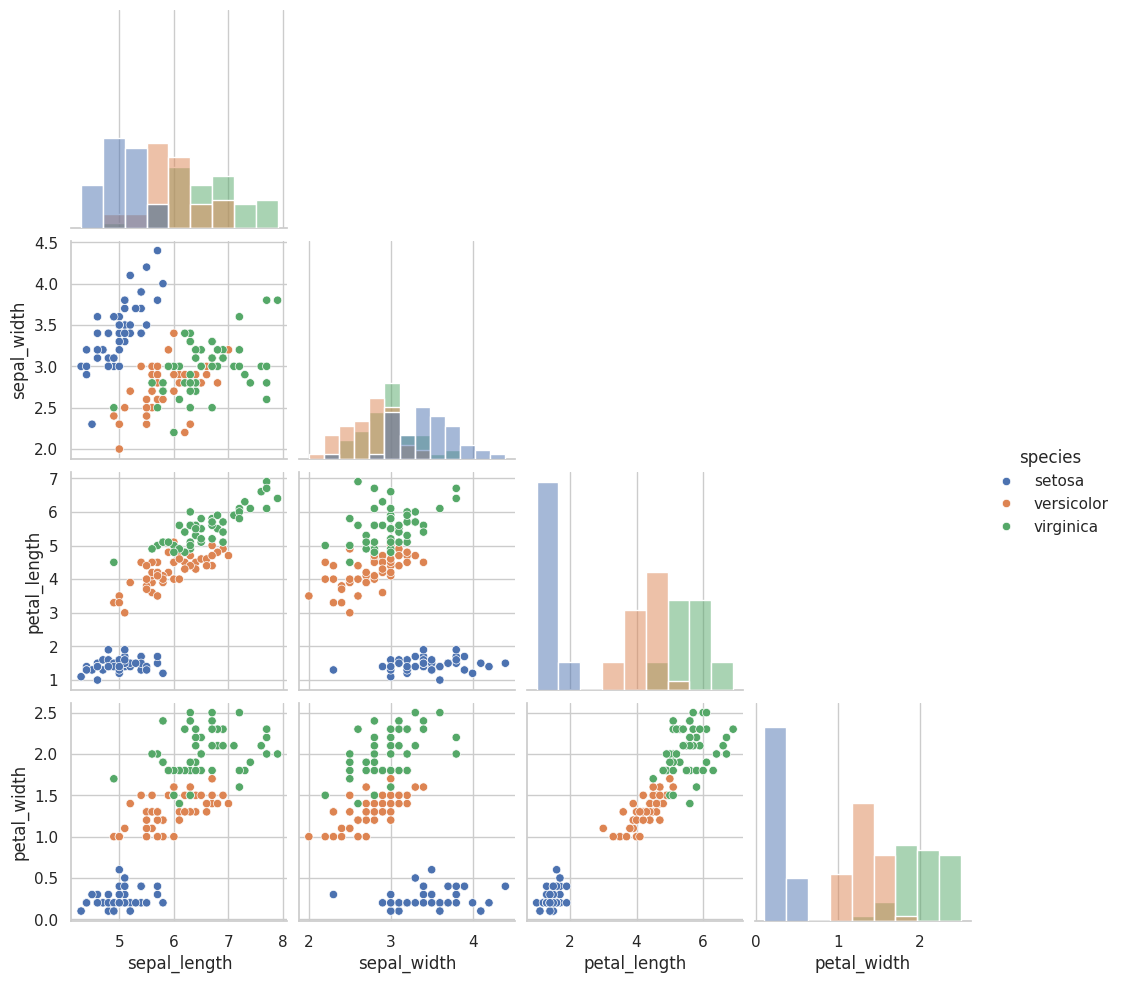

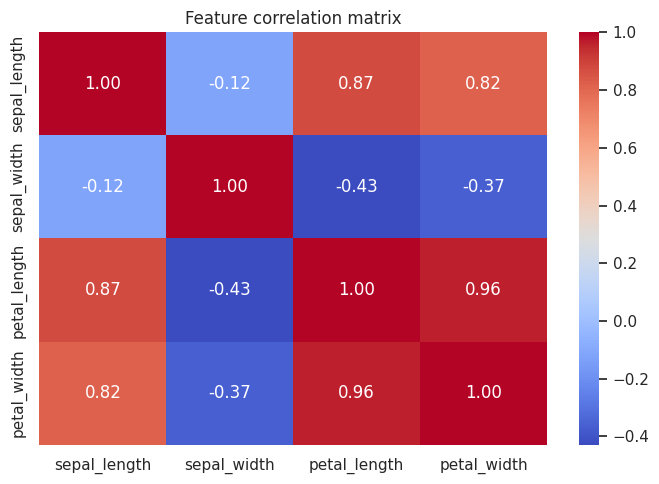

In [2]:
display(df.describe())
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="species", order=sorted(df.species.unique()))
plt.title("Observations per species")
plt.tight_layout()
plt.show()

sns.pairplot(df, hue="species", corner=True, diag_kind="hist")
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()


In [3]:
X = df.drop(columns="species")
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("\nTrain class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())


Train rows: 120 | Test rows: 30

Train class counts:
 species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Test class counts:
 species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [4]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE)
}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, "trained")


Logistic Regression trained
Decision Tree trained


In [5]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })
results = pd.DataFrame(rows).set_index("Model").sort_values("F1-score (macro)", ascending=False)
display(results.style.format("{:.3f}"))
print("Best by macro F1:", results.index[0])


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


Best by macro F1: Logistic Regression


In [6]:
for name, pred in predictions.items():
    print("\n" + "=" * 65 + "\n" + name)
    print(classification_report(y_test, pred, zero_division=0))



Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



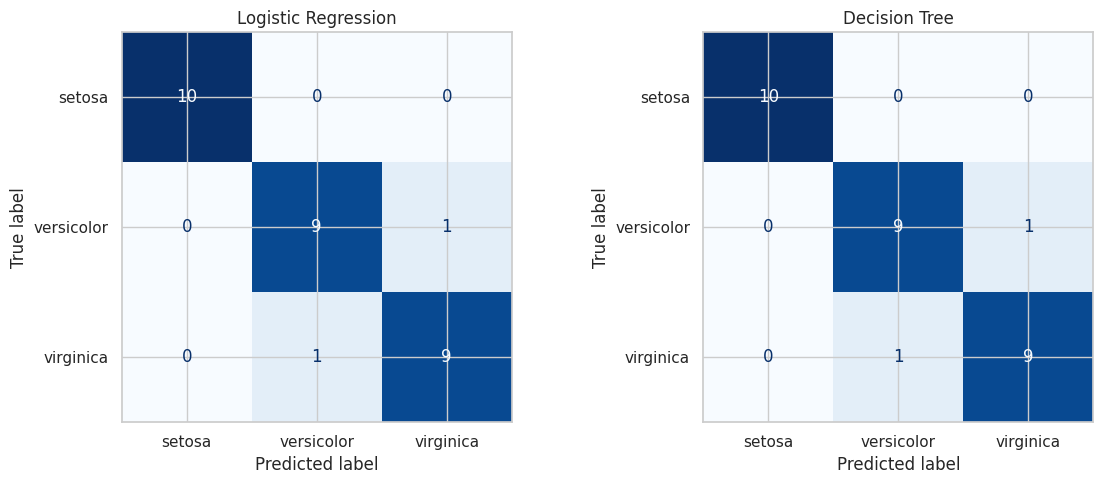

In [7]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()


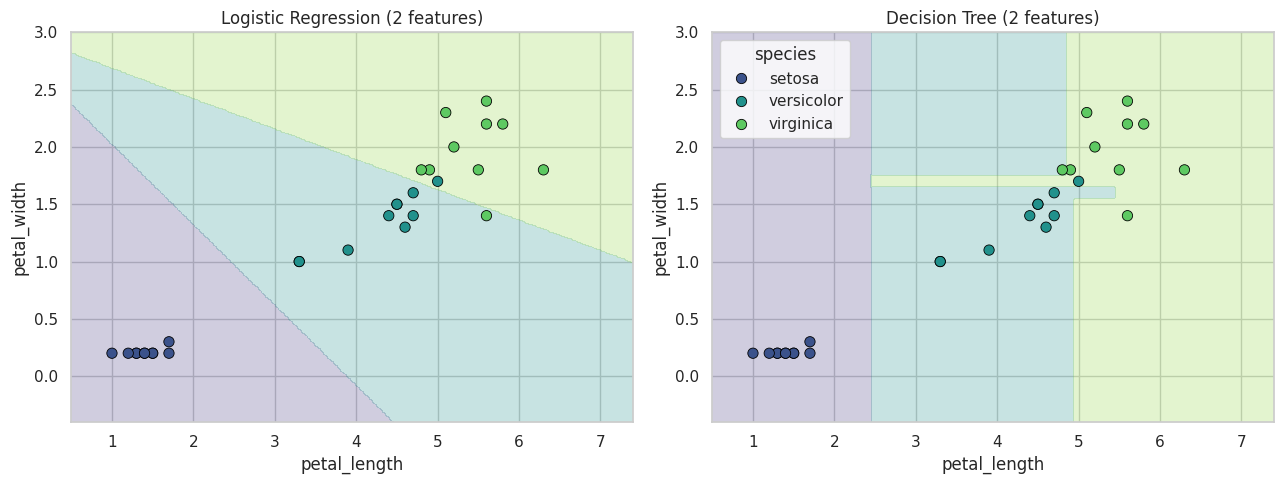

In [8]:
features_2d = ["petal_length", "petal_width"]
Xtr2 = X_train[features_2d]
labels = sorted(y.unique())
viz_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (2 features)": DecisionTreeClassifier(random_state=RANDOM_STATE)
}
x0, x1 = X[features_2d[0]].min() - .5, X[features_2d[0]].max() + .5
y0, y1 = X[features_2d[1]].min() - .5, X[features_2d[1]].max() + .5
xx, yy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=features_2d)
class_code = {label: i for i, label in enumerate(labels)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
test_plot = pd.DataFrame({
    features_2d[0]: X_test[features_2d[0]].to_numpy(),
    features_2d[1]: X_test[features_2d[1]].to_numpy(),
    "species": y_test.to_numpy()
})
for ax, (name, model) in zip(axes, viz_models.items()):
    model.fit(Xtr2, y_train)
    z = pd.Series(model.predict(grid)).map(class_code).to_numpy().reshape(xx.shape)
    ax.contourf(xx, yy, z, alpha=.25, levels=np.arange(len(labels)+1)-.5, cmap="viridis")
    sns.scatterplot(data=test_plot, x=features_2d[0], y=features_2d[1],
                    hue="species", hue_order=labels, palette="viridis",
                    edgecolor="black", s=55, ax=ax, legend=(ax is axes[1]))
    ax.set_title(name)
plt.tight_layout()
plt.show()
